# IBM heavy-hex lattice: a 27-qubit Falcon (ibmq_montreal), a Quantcore-PDK rebuild, step by step

**What the chip is.** IBM's heavy-hexagon lattice (Chamberland et al., PRX 10, 011022 (2020)), used on every IBM
processor since 2021: fixed-frequency transmons on the vertices (degree 3) and on the edges (degree 2) of a hexagonal
lattice, each pair coupled by a resonant bus, cross-resonance gates. The 27-qubit Falcon cut (ibmq_montreal, Falcon r4)
is two long rows of ten qubits, three bridge qubits between them and four "spur" qubits that would bridge to the next
rows of a larger lattice.

**This notebook rebuilds the chip in the Quantcore PDK; it is not a replica** (spec `docs/designs/ibm/ibm_falcon_27q.md`).
No layout of a heavy-hex chip is public; IBM's published device data set the graph and the targets, the layout is ours:
a **heavy-hex generator** (`heavy_hex(rows)`, step 1 — more or longer rows give Hummingbird- or Eagle-size lattices),
Quantum Metal's `TransmonPocket6` (IBM's pocket transmon, through `metal:`) with **Quantcore trilayer junctions** sized
per qubit by the PDK junction rule, one λ/2 meander bus per edge, a λ/4 readout per qubit on three feedlines
(airbridges where the middle feedline crosses the three bridge buses), Quantcore `BondPad`s, the PDK die frame (QCT),
sapphire 650 µm (εr 10.25), and the qcc LOM.

| | from the source | adapted here (why) |
|---|---|---|
| graph | ibmq_montreal coupling map (28 edges, IBM numbering 0–26); heavy-hex degree ≤ 3 (Chamberland) | generated by `heavy_hex([(1, 10), (0, 9)])` and mapped to IBM's numbering |
| f_q, α | Qiskit `FakeMontreal` Hamiltonian (2021-03-15): f_q 4.835–5.105 GHz, α −308 … −390 MHz | f_q matched per qubit with its junction (R_n 40–50 kΩ); α ≈ −150 MHz (R_n ≤ 50 kΩ caps L_J at 7.5 nH). Step 13 tries the two alternatives (#49) |
| J | `jq` of the same Hamiltonian: 1.31–2.01 MHz | set by the bus coupling pads (one pad size for all edges) |
| buses | "fixed-frequency transmons via microwave-resonant buses" (Chamberland §II C); frequencies not published | λ/2 meanders, 6.2 / 6.5 GHz on alternating row edges, 6.35 GHz on vertical edges (assumed) |
| readout | measurement LO 7.19–7.46 GHz per qubit (same backend) | λ/4 hangers on three feedlines (top, middle, bottom); Falcon reads out through an interposer (bump-bonded) |
| drive | dedicated drive lines (interposer) | through the readout feedlines (not drawn: planar single die) |
| junctions | Al/AlOx (not given) | Quantcore Nb/AlOx/Nb trilayer junctions (PDK rule: Δ 1.4 meV, R_n 40–50 kΩ) |
| pads | (no layout) | **PDK pad rule**: six feedline pads, each etch `frame.pad_edge` = 100 µm from the die edge (`edge="auto"`) |
| placement | (no layout) | the lattice sits at the die centre (checked in step 6) |
| cheese | (no layout to take it from) | **PDK band** (`cheese: "auto"`): no original cheese exists |

**Licences.** Device data from `qiskit-ibm-runtime` (Apache-2.0; local copy `build/external/qiskit_fake_backends/`)
and the cited paper; layout and code are ours (GPL, as the repository).

## 1 · Setup, the PDK and the heavy-hex graph

The notebook runs from the repository root; `_common` holds the table, snapshot, coupling and PDK helpers. `LIVE`
follows `QCC_LIVE` (live KLayout, or headless snapshots with `QCC_LIVE=0`).

In [1]:
%config InlineBackend.figure_formats = ["png"]
import math, os, sys
from collections import Counter
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                   # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
from _common import *                            # tables, snapshots, coupling and PDK helpers
from quantcore_circuits.designer import Designer
from quantcore_circuits.layouts.registry import trilayer_junction
from quantcore_circuits.circuit.bridges import rn_from_lj

LIVE = os.environ.get("QCC_LIVE", "1") == "1"   # live KLayout by default; QCC_LIVE=0 for batch runs
OUT = Path("examples/designs/ibm")

The PDK facts this chip relies on; the library applies each of them (frame and cheese in the build, the pad rule
through `edge=`, the junctions through `trilayer_junction`, the margins as DRC design warnings).

In [2]:
display(Markdown(pdk_facts_md()))

| PDK rule | value |
|---|---|
| process | `quantcore_nb_sapphire_v1` v3 |
| stack | sapphire 650 µm, εr 10.25, Nb film (λ_L 0.09 µm) |
| CPW default | centre 10 µm, gap 6 µm, bend radius 100 µm |
| die frame | standard die 7.5 × 7.5 mm; L dicing markers (1000/0, 25 µm wide), 3 × 3 alignment grids (1001/0) in 500 µm corner areas, boundary 100/0, device ID |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (`frame.pad_edge`) from the die edge (`edge="auto"`) |
| junctions | Nb/AlOx/Nb trilayer, Nb Δ 1.4 meV, R_n 40–50 kΩ (nominal 45 kΩ = 0.5 × 0.6 µm), C_J 50 fF/µm²; fingers 2/0 + 4/0, spacer 50/0 (+ 51–53/0 dose gradient) |
| qubit band | f_q 4–8 GHz (outside: DRC design warning `pdk_fq`) |
| cheese | the original design's own if it has one, else the PDK band: 5 µm squares, 20 µm gaps, 3 rows around the 3/0 keep-outs (chip param `cheese`: auto / pdk / original) |
| 3/0 keep-out | filled second-metal etch: routes CPW footprint + 10 µm, components etch bbox + 24 µm (or the cell's own) |
| corner rounding | fab only: r = 0.25 × the shortest dimension, ≤ 10 µm |

**The heavy-hex generator.** `heavy_hex(rows)` lays the graph out on a grid of columns and levels: long rows on even
levels, bridge qubits between them every fourth column (alternating offset), optional spur qubits above the top row
and below the bottom row. The Falcon cut is two long rows (columns 1–10 and 0–9), three bridges and four spurs; the
map to IBM's numbering is checked against the ibmq_montreal coupling map.

In [3]:
def heavy_hex(rows, offset=1, spurs=True):
    """Heavy-hex patch: ``rows`` = column ranges (c0, c1) of the long rows, bottom to top. Bridges join long rows r and
    r + 1 at columns c ≡ offset + 2r (mod 4); with ``spurs``, qubits also hang above the top row and below the bottom
    row where the next bridges would be (the Falcon cut has four). Returns ``sites`` {key: (column, level)} (level 2r:
    long rows, 2r + 1: bridges, −1 / 2R − 1: spurs) and ``edges`` [(key, key)]. Falcon 27:
    ``heavy_hex([(1, 10), (0, 9)])``; Eagle 127 (144 edges): ``heavy_hex([(0, 13)] + [(0, 14)] * 5 + [(1, 14)],
    offset=0, spurs=False)``."""
    sites, edges, n = {}, [], len(rows)
    for r, (c0, c1) in enumerate(rows):
        for c in range(c0, c1 + 1):
            sites[("L", r, c)] = (c, 2 * r)
            if c > c0:
                edges.append((("L", r, c - 1), ("L", r, c)))
    for r in range(n - 1):
        lo, hi = max(rows[r][0], rows[r + 1][0]), min(rows[r][1], rows[r + 1][1])
        for c in range(lo, hi + 1):
            if c % 4 == (offset + 2 * r) % 4:
                sites[("B", r, c)] = (c, 2 * r + 1)
                edges += [(("L", r, c), ("B", r, c)), (("B", r, c), ("L", r + 1, c))]
    ends = ((0, -1, (offset - 2) % 4), (n - 1, 2 * n - 1, (offset + 2 * (n - 1)) % 4)) if spurs else ()
    for r, level, off in ends:
        for c in range(rows[r][0], rows[r][1] + 1):
            if c % 4 == off:
                sites[("S", level, c)] = (c, level)
                edges.append((("S", level, c), ("L", r, c)) if level < 0 else (("L", r, c), ("S", level, c)))
    return sites, edges


SITES, EDGES = heavy_hex([(1, 10), (0, 9)])
IBM = {("L", 0, c): i for c, i in zip(range(1, 11), (3, 5, 8, 11, 14, 16, 19, 22, 25, 26))}
IBM |= {("L", 1, c): i for c, i in zip(range(0, 10), (0, 1, 4, 7, 10, 12, 15, 18, 21, 23))}
IBM |= {("B", 0, 1): 2, ("B", 0, 5): 13, ("B", 0, 9): 24, ("S", 3, 3): 6, ("S", 3, 7): 17, ("S", -1, 3): 9,
        ("S", -1, 7): 20}
NAME = {k: f"Q{IBM[k]}" for k in SITES}
COUPLING_MAP = [(0, 1), (1, 2), (1, 4), (2, 3), (3, 5), (4, 7), (5, 8), (6, 7), (7, 10), (8, 9), (8, 11), (10, 12),
                (11, 14), (12, 13), (12, 15), (13, 14), (14, 16), (15, 18), (16, 19), (17, 18), (18, 21), (19, 20),
                (19, 22), (21, 23), (22, 25), (23, 24), (24, 25), (25, 26)]
assert sorted(tuple(sorted((IBM[a], IBM[b]))) for a, b in EDGES) == COUPLING_MAP, "not the Falcon graph"
print(len(SITES), "qubits,", len(EDGES), "edges: the ibmq_montreal coupling map")

27 qubits, 28 edges: the ibmq_montreal coupling map


**Source targets**: ibmq_montreal (Qiskit `FakeMontreal`, Falcon r4, 2021-03-15; the Hamiltonian's variables ÷ 2π):
qubit frequencies, anharmonicities, readout LO centres and the exchange couplings `jq`.

In [4]:
F_Q = dict(enumerate([4.9107, 4.8347, 4.9824, 5.1049, 5.0037, 5.0331, 4.9506, 4.9057, 4.9082, 5.0446, 5.0819, 5.0341,
                      4.9723, 4.8683, 4.9609, 5.0339, 5.0855, 5.0721, 4.9814, 4.9832, 5.0822, 5.0733, 5.057, 4.9728,
                      5.0515, 4.9342, 4.9999]))                                         # GHz
ALPHA = dict(enumerate([-339.6, -324.5, -340.0, -335.3, -338.3, -337.4, -390.0, -323.2, -324.5, -338.1, -337.0,
                        -337.5, -322.0, -340.5, -323.2, -338.4, -337.3, -338.2, -326.2, -321.3, -337.7, -307.7,
                        -338.5, -337.3, -337.9, -322.9, -339.4]))                       # MHz
F_RO = dict(enumerate([7.2714, 7.3857, 7.2633, 7.3992, 7.3276, 7.3409, 7.4433, 7.1922, 7.1976, 7.4449, 7.2708,
                       7.3387, 7.4348, 7.3305, 7.3878, 7.3993, 7.2773, 7.4483, 7.1929, 7.2036, 7.4557, 7.3488,
                       7.3365, 7.4138, 7.2821, 7.3925, 7.282]))                        # GHz, meas LO centres
J_SRC = {(0, 1): 1.312, (1, 2): 1.399, (1, 4): 1.324, (2, 3): 1.36, (3, 5): 1.488, (4, 7): 1.441, (5, 8): 1.407,
         (6, 7): 2.014, (7, 10): 1.418, (8, 9): 1.416, (8, 11): 1.472, (10, 12): 1.583, (11, 14): 1.395,
         (12, 13): 1.359, (12, 15): 1.486, (13, 14): 1.36, (14, 16): 1.547, (15, 18): 1.695, (16, 19): 1.474,
         (17, 18): 1.525, (18, 21): 1.487, (19, 20): 1.461, (19, 22): 1.488, (21, 23): 1.418, (22, 25): 1.362,
         (23, 24): 1.305, (24, 25): 1.507, (25, 26): 1.433}                             # MHz

## 2 · The die and the frame

The die is sized to the lattice: 2.5 mm margins round ten 2.2 mm columns (27 × 15.2 mm). The build draws the PDK frame
(dicing L's, alignment grids, chip boundary, the device ID `HHX27` on a free edge).

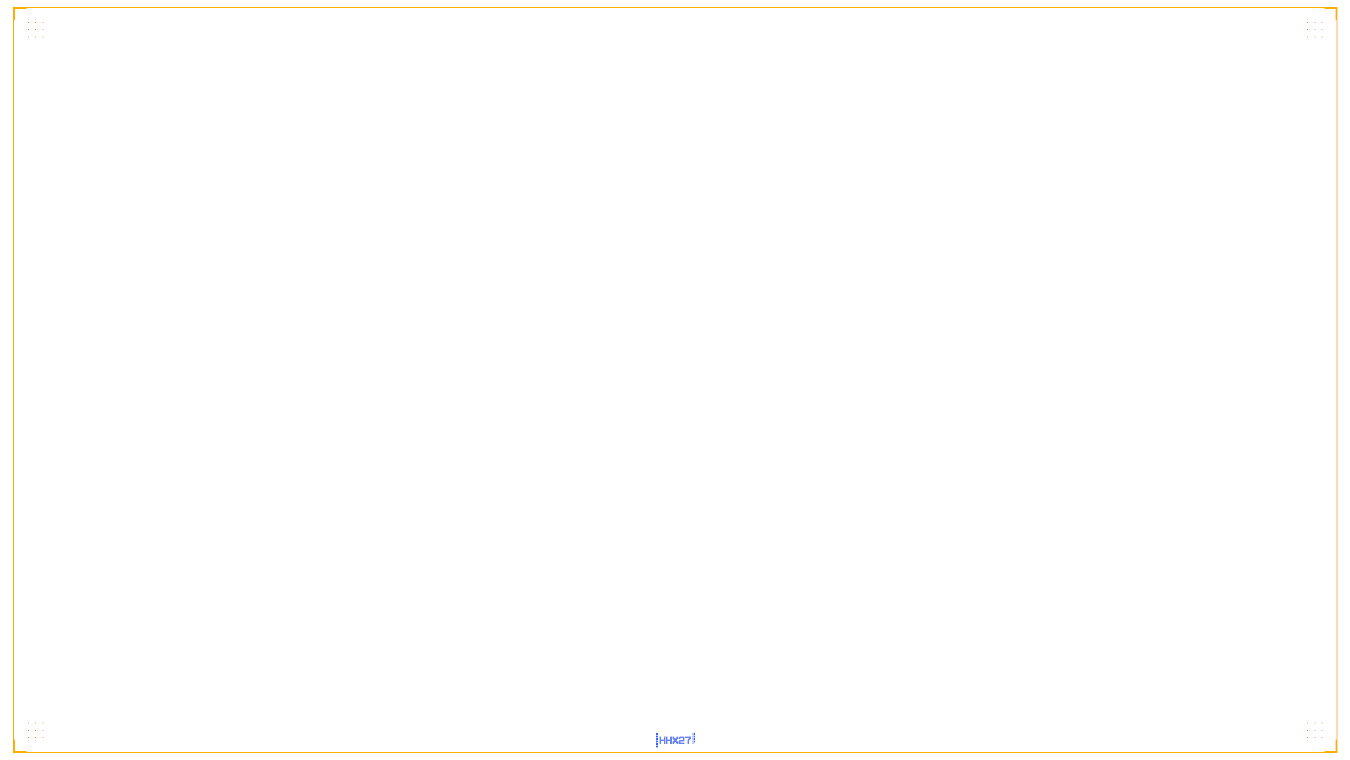

In [5]:
PH, PV = 2200, 2400                              # column pitch, level pitch
X0, Y0 = 2500, 5200                              # column 0, level 0 (the bottom long row)
W, H = X0 * 2 + 10 * PH, 15200
xy = lambda key: (X0 + SITES[key][0] * PH, Y0 + SITES[key][1] * PV)
d = Designer("ibm_falcon_27q", box=(0, 0, W, H), chip={"name_chip": "HHX27"}, live=LIVE)
snap(d, OUT / "ibm_falcon_27q_die.png", size=(1350, 760), width=640);

## 3 · Pads: the PDK pad rule

Three horizontal feedlines (above the top row, between the rows, below the bottom row), each between a pad on the west
and the east edge. The PDK puts each pad's outer etch edge **`frame.pad_edge` = 100 µm from the die edge**;
`edge="auto"` slides it perpendicular to its nearest edge until that holds, keeping its height.

In [6]:
Y_FEED = {"top": Y0 + 3 * PV + 1300, "mid": Y0 + PV + 700, "bot": Y0 - PV - 1300}
fpad = {}
for side, y in Y_FEED.items():
    fpad[side] = (d.add(f"FL_{side}_in", "BondPad", at=(1150, y), rot=-90, edge="auto"),
                  d.add(f"FL_{side}_out", "BondPad", at=(W - 1150, y), rot=90, edge="auto"))
rebuild(d)
display(Markdown(pads_md(d)))

| pad | cell / launcher | nearest die edge | outer etch → die edge (µm) | PDK rule |
|---|---|---|---|---|
| FL_top_in | `BondPad` | w | 100.0 | ✓ |
| FL_top_out | `BondPad` | e | 100.0 | ✓ |
| FL_mid_in | `BondPad` | w | 100.0 | ✓ |
| FL_mid_out | `BondPad` | e | 100.0 | ✓ |
| FL_bot_in | `BondPad` | w | 100.0 | ✓ |
| FL_bot_out | `BondPad` | e | 100.0 | ✓ |

## 4 · Components: pockets and trilayer junctions

**Junctions.** One Quantcore trilayer junction per qubit, its L_J solved with the LOM (step 9 a) so that f_q lands on
IBM's frequency; all R_n fall in 43–48 kΩ, inside the PDK window.

In [7]:
LJ = {0: 7.172, 1: 7.096, 2: 6.814, 3: 6.492, 4: 6.797, 5: 6.674, 6: 7.034, 7: 6.883, 8: 6.891, 9: 6.782,
      10: 6.596, 11: 6.671, 12: 6.720, 13: 7.128, 14: 6.735, 15: 6.718, 16: 6.541, 17: 6.710, 18: 6.681,
      19: 6.691, 20: 6.684, 21: 6.617, 22: 6.613, 23: 6.840, 24: 6.634, 25: 6.806, 26: 6.900}  # nH (R_n 43–48 kΩ)
rn = {i: rn_from_lj(trilayer_junction("metal:TransmonPocket6", lj_nH=lj)[1]["Lj_nH"]) / 1e3 for i, lj in LJ.items()}
print(f"drawn R_n {min(rn.values()):.1f}–{max(rn.values()):.1f} kΩ")

drawn R_n 43.3–47.9 kΩ


**Connection pads.** Each pocket gets a bus pad towards each neighbour (corner pads ±x for row neighbours, middle pads
±y for vertical ones) and a readout pad: opposite its vertical bus, or away from the patch; a bridge qubit (buses both
up and down) reads out from a corner pad towards +x. `ro_side` records which feedline each readout uses.

Counter({2: 13, 3: 8, 1: 6}) qubits by degree


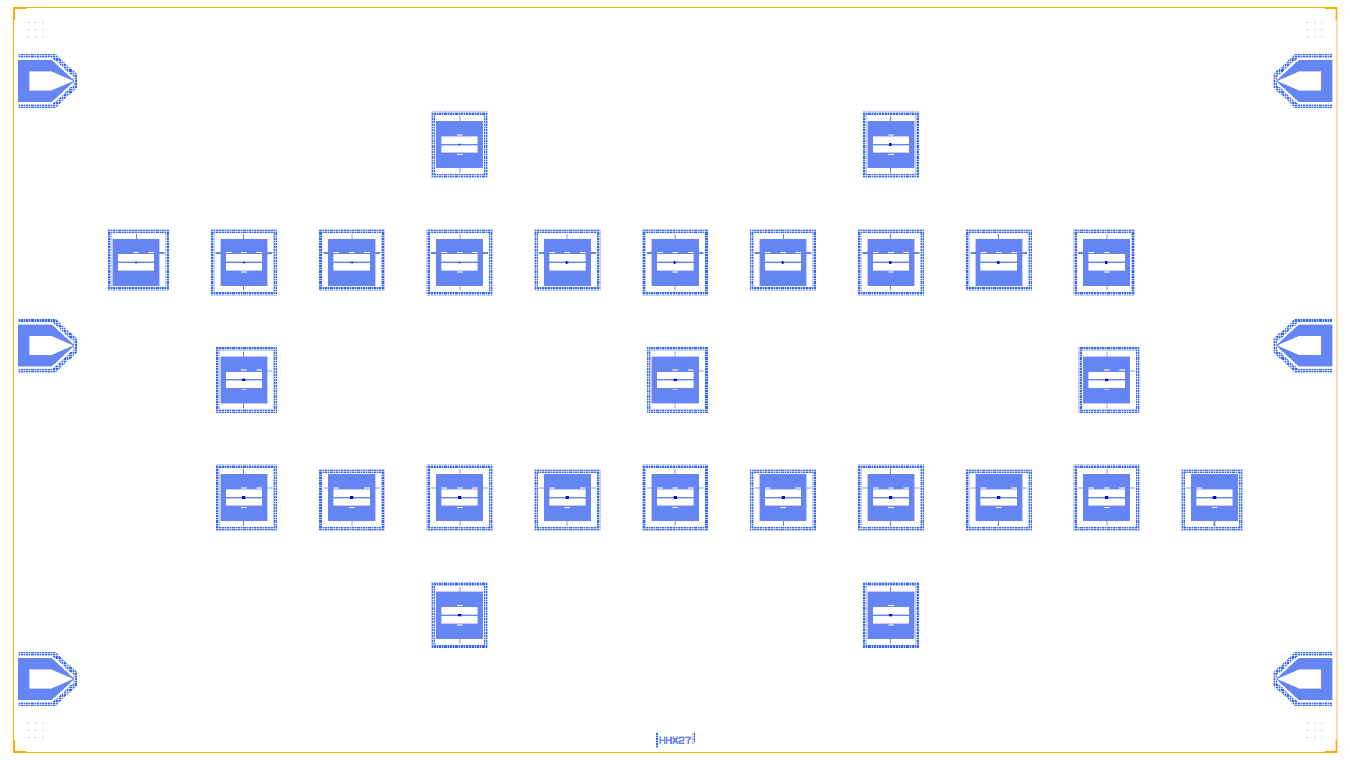

In [8]:
POCKET = dict(pad_width=750, pad_height=160, pad_gap=20, pocket_width=950, pocket_height=950)
BUS_PAD, RO_PAD = 125, 120
nbr = {k: [] for k in SITES}
for a, b in EDGES:
    nbr[a].append(b)
    nbr[b].append(a)
pads, ro_side = {}, {}
top_row = max(lv for (_, lv) in SITES.values() if lv % 2 == 0)
for k, (c, lvl) in SITES.items():
    p = {}
    for o in nbr[k]:
        oc, ol = SITES[o]
        if ol == lvl:
            p["bw" if oc < c else "be"] = {"loc_W": -1 if oc < c else 1, "loc_H": 1, "pad_width": BUS_PAD}
        else:
            p["bn" if ol > lvl else "bs"] = {"loc_W": 0, "loc_H": 1 if ol > lvl else -1, "pad_width": BUS_PAD}
    if "bn" in p and "bs" in p:                   # a bridge: the readout leaves from a corner pad, towards +x, up
        p["ro"], up = {"loc_W": 1, "loc_H": 1, "pad_width": RO_PAD}, True
    else:                                         # opposite its vertical bus; without one, away from the patch
        up = "bs" in p if ("bn" in p or "bs" in p) else lvl >= top_row
        p["ro"] = {"loc_W": 0, "loc_H": 1 if up else -1, "pad_width": RO_PAD}
    y = Y0 + lvl * PV                             # the nearest feedline in the readout's direction
    ro_side[k] = min((f for f, yf in Y_FEED.items() if (yf > y) == up), key=lambda f: abs(Y_FEED[f] - y))
    pads[k] = p
q = {}
for k in SITES:
    i = IBM[k]
    params, junction = trilayer_junction("metal:TransmonPocket6", lj_nH=LJ[i])
    q[k] = d.add(NAME[k], "metal:TransmonPocket6", at=xy(k), junction=junction, connection_pads=pads[k],
                 **POCKET, **params)
print(Counter(len(nbr[k]) for k in SITES), "qubits by degree")
snap(d, OUT / "ibm_falcon_27q_components.png", size=(1350, 760), width=640);

## 5 · Routes: buses, feedlines and readouts

- **Buses:** one λ/2 meander per edge, `L ≈ 60400 µm·GHz / f_bus` (the pad loading calibrated with the LOM) for an
  assumed plan: 6.2 / 6.5 GHz on alternating row edges, 6.35 GHz on vertical edges. A vertical bus leaves the lower
  qubit straight for 275 µm (the middle feedline crosses the bridge buses there).
- **Feedlines:** straight through-lines between their side pads; the middle one crosses the three bridge buses on
  **airbridges** (`d.waypoint(..., airbridge=True)`).
- **Readouts:** λ/4 from the readout pad into a 300 µm **hanger** on the chosen feedline, shorted at its end; the
  lengths are set for IBM's readout frequencies with the LOM. `fl.hanger(near=(x, y))` centres the coupler at the
  feedline point nearest (x, y), here 150 µm to the right of where the readout reaches the line: given by position, not by
  arclength from the pad, the coupler stays at its qubit when the pads (and so the feedline's start) move.

In [9]:
def bus_f(a, b):
    """Assumed bus frequency plan (GHz): alternating 6.2 / 6.5 along the long rows, 6.35 on vertical edges."""
    (ca, la), (cb, lb) = SITES[a], SITES[b]
    return (6.2 if min(ca, cb) % 2 == 0 else 6.5) if la == lb else 6.35


L_BUS = {}                                       # λ/2 bus lengths per edge
for a, b in EDGES:
    (ca, la), (cb, lb) = SITES[a], SITES[b]
    if la == lb:
        lo, hi = (a, b) if ca < cb else (b, a)
        pa, pb, nodes = q[lo].be, q[hi].bw, None
    else:
        lo, hi = (a, b) if la < lb else (b, a)
        x, y = xy(lo)
        pa, pb, nodes = q[lo].bn, q[hi].bs, [(x, y + 850)]
    name = f"B_{IBM[lo]}_{IBM[hi]}"
    L_BUS.setdefault(name, round(60400 / bus_f(a, b)))      # ≈ λ/2 with the pad loading (calibrated, step 9)
    d.route(name, pa, pb, meander=L_BUS[name], r=50, nodes=nodes)
fl = {}
for side, y in Y_FEED.items():
    a, b = fpad[side]
    bridges = [d.waypoint((xy(k)[0], y), airbridge=True) for k in SITES if k[0] == "B"] if side == "mid" else None
    fl[side] = d.route(f"FL_{side}", a.a, b.a, nodes=bridges)
K_LEN = 300                                      # readout hanger coupling length
L_RO = {0: 4088, 1: 4020, 2: 4093, 3: 4013, 4: 4054, 5: 4047, 6: 3988, 7: 4137, 8: 4132, 9: 3987, 10: 4088,
        11: 4049, 12: 3991, 13: 4053, 14: 4020, 15: 4012, 16: 4085, 17: 3985, 18: 4136, 19: 4129, 20: 3981,
        21: 4042, 22: 4050, 23: 4004, 24: 4082, 25: 4017, 26: 4083}                 # λ/4 readouts (µm), for F_RO
for k in SITES:
    i, (x, y) = IBM[k], xy(k)
    yf = Y_FEED[ro_side[k]]
    x_start = x + 1600 if k[0] == "B" else x                 # a bridge's readout runs +x from its corner pad
    side = "left" if yf < y else "right"                     # the feedline travels +x: left = above it
    hang = fl[ro_side[k]].hanger(near=(x_start + K_LEN / 2, yf), length=K_LEN, side=side, ground_gap=4,
                                 end="short")
    nodes = [(x_start, y + 190)] if k[0] == "B" else None
    d.route(f"R{i}", q[k].ro, hang, meander=L_RO[i], r=50, nodes=nodes)
rebuild(d)
print({k: round(v) for k, v in d.result.route_lengths().items() if not k.startswith("FL")})

{'B_3_5': 9292, 'B_5_8': 9742, 'B_8_11': 9292, 'B_11_14': 9742, 'B_14_16': 9292, 'B_16_19': 9742, 'B_19_22': 9292, 'B_22_25': 9742, 'B_25_26': 9292, 'B_0_1': 9742, 'B_1_4': 9292, 'B_4_7': 9742, 'B_7_10': 9292, 'B_10_12': 9742, 'B_12_15': 9292, 'B_15_18': 9742, 'B_18_21': 9292, 'B_21_23': 9742, 'B_3_2': 9512, 'B_2_1': 9512, 'B_14_13': 9512, 'B_13_12': 9512, 'B_25_24': 9512, 'B_24_23': 9512, 'B_9_8': 9512, 'B_20_19': 9512, 'B_7_6': 9512, 'B_18_17': 9512, 'R3': 4013, 'R5': 4047, 'R8': 4132, 'R11': 4049, 'R14': 4020, 'R16': 4085, 'R19': 4129, 'R22': 4050, 'R25': 4017, 'R26': 4083, 'R0': 4088, 'R1': 4020, 'R4': 4054, 'R7': 4137, 'R10': 4088, 'R12': 3991, 'R15': 4012, 'R18': 4136, 'R21': 4042, 'R23': 4004, 'R2': 4093, 'R13': 4053, 'R24': 4082, 'R9': 3987, 'R20': 3981, 'R6': 3988, 'R17': 3985}


## 6 · PDK placement, targets and FEM groups

`center_in_die(d)` measures the bounding box of all instances and routes and shifts them to centre it; the die was
sized round the lattice, so it returns (0, 0).

Targets: IBM's f_q and α per qubit and its readout frequency. FEM boxes: a vertex qubit (Q12) with its three buses and
neighbours (C-matrix), and Q0 with its readout (C-matrix and eigenmode). The layout is complete and is saved.

In [10]:
print("centring shift (µm):", center_in_die(d))
d.targets(**{f"Q{i}": {"f_q_GHz": F_Q[i], "alpha_MHz": ALPHA[i]} for i in F_Q},
          **{f"R{i}": {"f_GHz": F_RO[i]} for i in F_RO})
d.sim_group("vertex_Q12", ["Q10", "Q12", "Q13", "Q15", "B_10_12", "B_13_12", "B_12_15"], margin_um=100,
            analyses=["q3d_cmatrix"])
d.sim_group("Q0_read", ["Q0", "R0"], margin_um=100, analyses=["q3d_cmatrix", "eigenmode_epr"])
DESIGN = d.save(OUT / "ibm_falcon_27q.json")
print(d, "→", DESIGN)

centring shift (µm): (0.0, 0.0)
<Designer ibm_falcon_27q: 33 instances, 58 routes, live=False> → examples\designs\ibm\ibm_falcon_27q.json


## 7 · DRC

- **errors:** none expected;
- **warnings:** `dangling_port` on the `squid_a` / `squid_b` junction attachment points of the 27 pockets (the cell
  draws the trilayer junction across the pad gap itself);
- **PDK design warnings:** none expected (R_n in the window, f_q targets in 4–8 GHz, pads at 100 µm).

This run: **0 errors · 54 warnings (`dangling_port`) · 0 PDK design warnings**.

In [11]:
rebuild(d)
rep = d.drc()
display(Markdown(drc_md(rep)))
display(Markdown(pdk_report(d)))

**0 errors · 54 warnings · 0 PDK design warnings** (DRC clean)

| kind | rule | count | first message |
|---|---|---|---|
| warning | `dangling_port` | 54 | Q0.squid_a is not connected (no route or snap) |

| check | value |
|---|---|
| cheese | PDK band (drawn in the build) |
| content centre − die centre | (+0, +0) µm |
| junction types | Quantcore Junction × 27 |
| PDK design warnings | 0 (none) |

## 8 · Netlist and LOM

27 floating pocket transmons (two pad nodes each, the drawn trilayer L_J / C_J), a node per connection pad; each edge's
meander is a λ/2 `TLres` joining the two bus pads; each readout a λ/4 `TLres` with a hanger κ into its feedline
(`FL_top`, `FL_mid`, `FL_bot`; the airbridges keep the middle one one conductor). The table lists the counts and the
first rows only.

In [12]:
lb = d.lom()
md = netlist_md(lb)
display(Markdown("\n".join(md.splitlines()[:30]) + "\n\n…"))
print(Counter(b.type for b in lb.model.branches.values()), "| unconnected ports:", lb.unconnected)

**113 nodes · 445 branches · 0 controls · 0 unconnected ports**

| node | FEM nets |
|---|---|
| `gnd` | ground |
| `FL_top` | `FL_top`, `FL_top_in.pad`, `FL_top_out.pad` |
| `FL_mid` | `FL_mid`, `FL_mid_in.pad`, `FL_mid_out.pad` |
| `FL_bot` | `FL_bot`, `FL_bot_in.pad`, `FL_bot_out.pad` |
| `Q3.island1` | `Q3.island1` |
| `Q3.island2` | `Q3.island2` |
| `Q3.be` | `Q3.be`, `Q5.bw` |
| `Q3.bn` | `Q3.bn`, `Q2.bs` |
| `Q3.ro` | `Q3.ro` |
| `Q5.island1` | `Q5.island1` |
| `Q5.island2` | `Q5.island2` |
| `Q5.be` | `Q5.be`, `Q8.bw` |
| `Q5.ro` | `Q5.ro` |
| `Q8.island1` | `Q8.island1` |
| `Q8.island2` | `Q8.island2` |
| `Q8.be` | `Q8.be`, `Q11.bw` |
| `Q8.bs` | `Q8.bs`, `Q9.bn` |
| `Q8.ro` | `Q8.ro` |
| `Q11.island1` | `Q11.island1` |
| `Q11.island2` | `Q11.island2` |
| `Q11.be` | `Q11.be`, `Q14.bw` |
| `Q11.ro` | `Q11.ro` |
| `Q14.island1` | `Q14.island1` |
| `Q14.island2` | `Q14.island2` |
| `Q14.be` | `Q14.be`, `Q16.bw` |
| `Q14.bn` | `Q14.bn`, `Q13.bs` |

…

Counter({'C': 330, 'TLres': 55, 'JJ': 27, 'HANGER': 27, 'R': 6}) | unconnected ports: []


## 9 · LOM simulation

**(a) Qubit + readout pairs** (QuTiP dressed; IBM's values in brackets). L_J of step 4 and the readout lengths were
solved with these groups.

This run: f_q 4.826–5.101 GHz, within 30 MHz of IBM's; α −143 … −151 MHz (IBM −308 … −390, step 13); f_r
7.082–7.340 GHz, 1.5 % (≈ 110 MHz) below IBM's measurement LOs: the lengths were set before the Nb film's kinetic
inductance (PDK `kinetic`) entered the LOM, which makes every line ≈ 1.5 % slower (flagged, not retuned); κ
0.31–0.34 MHz; χ −0.35 … −0.62 MHz.

In [13]:
read = {f"Q{i}+R{i}": [f"Q{i}", f"R{i}", f"FL_{ro_side[k]}"] for k, i in sorted(IBM.items(), key=lambda t: t[1])}
results = simulate_groups(d, read)
display(Markdown(groups_md(results, d.data["targets"])))

| group | qubit | f_q (GHz) | α (MHz) | resonator | f_r (GHz) | κ (MHz) | χ (MHz) |
|---|---|---|---|---|---|---|---|
| Q0+R0 | Q0 | 4.9289 (4.9107) | -150.9 (-339.6) | R0 | 7.1602 (7.2714) | 0.317 | -0.422 |
| Q1+R1 | Q1 | 4.8257 (4.8347) | -144.3 (-324.5) | R1 | 7.2714 (7.3857) | 0.331 | -0.347 |
| Q2+R2 | Q2 | 4.9658 (4.9824) | -146.2 (-340) | R2 | 7.152 (7.2633) | 0.316 | -0.47 |
| Q3+R3 | Q3 | 5.101 (5.1049) | -144.6 (-335.3) | R3 | 7.2858 (7.3992) | 0.333 | -0.603 |
| Q4+R4 | Q4 | 5.0275 (5.0037) | -146.8 (-338.3) | R4 | 7.215 (7.3276) | 0.324 | -0.385 |
| Q5+R5 | Q5 | 5.0095 (5.0331) | -145.5 (-337.4) | R5 | 7.2287 (7.3409) | 0.325 | -0.577 |
| Q6+R6 | Q6 | 4.9678 (4.9506) | -149.8 (-390) | R6 | 7.3282 (7.4433) | 0.339 | -0.504 |
| Q7+R7 | Q7 | 4.9144 (4.9057) | -142.9 (-323.2) | R7 | 7.0819 (7.1922) | 0.307 | -0.6 |
| Q8+R8 | Q8 | 4.9201 (4.9082) | -143.4 (-324.5) | R8 | 7.088 (7.1976) | 0.307 | -0.406 |
| Q9+R9 | Q9 | 5.0626 (5.0446) | -148.8 (-338.1) | R9 | 7.33 (7.4449) | 0.339 | -0.541 |
| Q10+R10 | Q10 | 5.0737 (5.0819) | -146.3 (-337) | R10 | 7.1593 (7.2708) | 0.317 | -0.412 |
| Q11+R11 | Q11 | 5.0095 (5.0341) | -145.5 (-337.5) | R11 | 7.2254 (7.3387) | 0.325 | -0.577 |
| Q12+R12 | Q12 | 4.9666 (4.9723) | -143 (-322) | R12 | 7.3207 (7.4348) | 0.338 | -0.377 |
| Q13+R13 | Q13 | 4.8706 (4.8683) | -147.1 (-340.5) | R13 | 7.2175 (7.3305) | 0.324 | -0.423 |
| Q14+R14 | Q14 | 4.9608 (4.9609) | -142.5 (-323.2) | R14 | 7.2735 (7.3878) | 0.331 | -0.568 |
| Q15+R15 | Q15 | 5.0276 (5.0339) | -146.8 (-338.4) | R15 | 7.2853 (7.3993) | 0.333 | -0.372 |
| Q16+R16 | Q16 | 5.0554 (5.0855) | -145 (-337.3) | R16 | 7.1663 (7.2773) | 0.317 | -0.618 |
| Q17+R17 | Q17 | 5.0626 (5.0721) | -148.8 (-338.2) | R17 | 7.3334 (7.4483) | 0.339 | -0.54 |
| Q18+R18 | Q18 | 4.9607 (4.9814) | -142.5 (-326.2) | R18 | 7.0836 (7.1929) | 0.307 | -0.623 |
| Q19+R19 | Q19 | 4.9665 (4.9832) | -142.9 (-321.3) | R19 | 7.0929 (7.2036) | 0.308 | -0.421 |
| Q20+R20 | Q20 | 5.0626 (5.0822) | -148.9 (-337.7) | R20 | 7.3403 (7.4557) | 0.34 | -0.539 |
| Q21+R21 | Q21 | 5.0737 (5.0733) | -146.3 (-307.7) | R21 | 7.235 (7.3488) | 0.326 | -0.396 |
| Q22+R22 | Q22 | 5.0555 (5.057) | -145.1 (-338.5) | R22 | 7.2239 (7.3365) | 0.325 | -0.6 |
| Q23+R23 | Q23 | 4.9659 (4.9728) | -146.2 (-337.3) | R23 | 7.2997 (7.4138) | 0.335 | -0.438 |
| Q24+R24 | Q24 | 5.0586 (5.0515) | -145.3 (-337.9) | R24 | 7.17 (7.2821) | 0.318 | -0.503 |
| Q25+R25 | Q25 | 4.9146 (4.9342) | -142.9 (-322.9) | R25 | 7.2786 (7.3925) | 0.332 | -0.547 |
| Q26+R26 | Q26 | 5.0154 (4.9999) | -149.3 (-339.4) | R26 | 7.1696 (7.282) | 0.318 | -0.564 |

**(b) Exchange coupling and ZZ on every edge** (qubit – bus – qubit, `exchange_coupling`: half the splitting at the
avoided crossing when the second qubit's L_J is swept through the first's frequency; ZZ at the design frequencies),
next to IBM's `jq`. About 15 s per edge, ≈ 7 min in all.

**Frequency collisions.** IBM's frequency pattern was laid out for α ≈ −330 MHz; with the PDK's α ≈ −145 MHz some of
its neighbour detunings (≈ 0.1–0.2 GHz) fall near |Δ| ≈ |α|, where |11⟩ meets |20⟩ / |02⟩ and the static ZZ grows to
hundreds of kHz or MHz (look for the large |ZZ| rows: Q8–Q9, Q1–Q2, Q2–Q3, Q22–Q25, Q24–Q25, Q7–Q10). Step 13 tries
the two ways out.

This run: J 0.90–1.64 MHz (IBM 1.30–2.01); ZZ on the six colliding edges Q8–Q9 2.02 MHz, Q1–Q2 −1.81 MHz, Q2–Q3
1.08 MHz, Q22–Q25 476 kHz, Q24–Q25 336 kHz and Q7–Q10 −261 kHz; on the other 22 edges −25 … +126 kHz.

In [14]:
BUS = {}
for a, b in EDGES:
    lo, hi = sorted((IBM[a], IBM[b]))
    BUS[(lo, hi)] = next(n for n in d.data["routes"] if n in (f"B_{lo}_{hi}", f"B_{hi}_{lo}"))
J = {}
for (lo, hi), bus in BUS.items():
    J[f"Q{lo}-Q{hi}"] = exchange_coupling(d, [f"Q{lo}", bus, f"Q{hi}"], f"Q{lo}", f"Q{hi}", n=4)
    J[f"Q{lo}-Q{hi}"]["bus"] = bus
display(Markdown(exchange_md(J, {f"Q{a}-Q{b}": v for (a, b), v in J_SRC.items()})))

| pair | f_a (GHz) | f_b (GHz) | J (MHz) | target J (MHz) | ZZ (kHz) |
|---|---|---|---|---|---|
| Q3-Q5 | 5.1039 | 5.0123 | 1.46 | 1.49 | 70.7 |
| Q5-Q8 | 5.0121 | 4.9196 | 1.52 | 1.41 | 74.5 |
| Q8-Q11 | 4.9198 | 5.0124 | 1.11 | 1.47 | 51.1 |
| Q11-Q14 | 5.0121 | 4.9663 | 1.52 | 1.4 | 51.9 |
| Q14-Q16 | 4.9665 | 5.0584 | 1.17 | 1.55 | 56.4 |
| Q16-Q19 | 5.0581 | 4.9659 | 1.62 | 1.47 | 84.4 |
| Q19-Q22 | 4.9661 | 5.0584 | 1.17 | 1.49 | 57 |
| Q22-Q25 | 5.0581 | 4.9200 | 1.62 | 1.36 | 476 |
| Q25-Q26 | 4.9202 | 5.0150 | 1.18 | 1.43 | 56.4 |
| Q0-Q1 | 4.9284 | 4.8251 | 1.3 | 1.31 | 58.3 |
| Q1-Q4 | 4.8253 | 5.0272 | 0.895 | 1.32 | -25.3 |
| Q4-Q7 | 5.0270 | 4.9200 | 1.39 | 1.44 | 76.9 |
| Q7-Q10 | 4.9202 | 5.0734 | 0.994 | 1.42 | -261 |
| Q10-Q12 | 5.0731 | 4.9659 | 1.49 | 1.58 | 88.6 |
| Q12-Q15 | 4.9661 | 5.0272 | 1.05 | 1.49 | 31.4 |
| Q15-Q18 | 5.0270 | 4.9663 | 1.39 | 1.7 | 45.9 |
| Q18-Q21 | 4.9665 | 5.0734 | 1.05 | 1.49 | 58.8 |
| Q21-Q23 | 5.0731 | 4.9651 | 1.58 | 1.42 | 101 |
| Q2-Q3 | 4.9620 | 5.1037 | 1.5 | 1.36 | 1.08e+03 |
| Q1-Q2 | 4.8192 | 4.9653 | 1.31 | 1.4 | -1.81e+03 |
| Q13-Q14 | 4.8669 | 4.9665 | 1.26 | 1.36 | 78.4 |
| Q12-Q13 | 4.9598 | 4.8701 | 1.55 | 1.36 | 81.1 |
| Q24-Q25 | 5.0546 | 4.9201 | 1.59 | 1.51 | 336 |
| Q23-Q24 | 4.9620 | 5.0580 | 1.5 | 1.3 | 100 |
| Q8-Q9 | 4.9135 | 5.0619 | 1.55 | 1.42 | 2.02e+03 |
| Q19-Q20 | 4.9598 | 5.0619 | 1.64 | 1.46 | 126 |
| Q6-Q7 | 4.9672 | 4.9201 | 1.37 | 2.01 | 42.1 |
| Q17-Q18 | 5.0619 | 4.9664 | 1.54 | 1.52 | 77 |

## 10 · FEM: send the job

Three jobs: a Q3D C-matrix job for the vertex qubit Q12 with its three buses and neighbours, and for Q0 a C-matrix
and an eigenmode job with its readout. Simulation exports never carry cheese; airbridges are left out unless
`build_simulation(..., airbridges=True)`. Exporting again replaces a job folder, results included.

`RUN_FEM = False` only exports. With `RUN_FEM = True` and AEDT 2024 R1 (or newer) here, `send_fem_jobs` solves each job in
a **new batch, non-graphical AEDT** (`solve_job`); an open AEDT window is never touched. Elsewhere:
`qcc hfss solve build/jobs/<job>`.

In [15]:
RUN_FEM = False                                  # True: solve the jobs now in a new batch AEDT (2024 R1 or newer)
jobs = export_sims(DESIGN, ["vertex_Q12", "Q0_read"])
jobs_eig = export_sims(DESIGN, ["Q0_read"], analysis="eigenmode_epr")
display(Markdown(jobs_md(jobs) + "\n" + jobs_md(jobs_eig).split("\n", 2)[2]))
if RUN_FEM:
    send_fem_jobs(DESIGN, ["vertex_Q12", "Q0_read"], run=True)   # each group's own analyses

| group | job | ports (number · kind · name) | C-matrix nets |
|---|---|---|---|
| vertex_Q12 | `build/jobs/ibm_falcon_27q_vertex_Q12_q3d_cmatrix` | 1 · junction · `Q10.junction`<br>2 · junction · `Q12.junction`<br>3 · junction · `Q13.junction`<br>4 · junction · `Q15.junction`<br>5 · waveguide · `Q10.be`<br>6 · waveguide · `Q12.bw`<br>7 · waveguide · `Q12.be`<br>8 · waveguide · `Q15.bw`<br>9 · waveguide · `Q13.bn`<br>10 · waveguide · `Q12.bs`<br>11 · edge · `B_14_13`<br>12 · edge · `B_15_18`<br>13 · edge · `B_7_10`<br>14 · edge · `FL_mid` | `Q10.island2`, `Q12.island2`, `Q13.island2`, `Q15.island2`, `Q10.be`, `Q12.bw`, `Q12.be`, `Q15.bw`, `Q13.bn`, `Q12.bs`, `B_14_13`, `B_15_18`, `B_7_10`, `FL_mid`, `Q13.island1`, `Q10.island1`, `Q12.island1`, `Q15.island1` |
| Q0_read | `build/jobs/ibm_falcon_27q_Q0_read_q3d_cmatrix` | 1 · junction · `Q0.junction`<br>2 · waveguide · `Q0.ro`<br>3 · edge · `B_0_1` | `Q0.island2`, `Q0.ro`, `B_0_1`, `Q0.island1` |
| Q0_read | `build/jobs/ibm_falcon_27q_Q0_read_eigenmode_epr` | 1 · junction · `Q0.junction`<br>2 · edge_lumped · `B_0_1`<br>3 · edge_lumped · `FL_top`<br>4 · edge_lumped · `FL_top` | `Q0.island2`, `B_0_1`, `FL_top`, `FL_top#2`, `Q0.island1` |

## 11 · Bring the results back

With results in `build/jobs/<job>/results/results.json`, `fill(model, design, job)` replaces the LOM capacitance
estimates by net name (Q12's and its neighbours' `island1` / `island2`, the bus pads) next to the estimates; steps 9
(a)–(b) can then be run again on the extracted values. Until a solve has run, the cell says what would appear.

In [16]:
filled, md = fem_back(lb.model, DESIGN, {**{f"{g} · q3d": v for g, v in jobs.items()},
                                         **{f"{g} · eigenmode": v for g, v in jobs_eig.items()}})
display(Markdown(md))

No FEM results yet for vertex_Q12 · q3d, Q0_read · q3d, Q0_read · eigenmode: after a solve, `results/results.json` appears in each job folder and this cell shows the C-matrix (or eigenmode) values next to the LOM estimates; `simulate(filled)` then re-runs the LOM on the extracted values.

## 12 · Iterate: change one property and re-simulate

A readout is tuned by its length: R0 is shortened by 100 µm (≈ 2.5 %), so f_r rises by about as much and the qubit's
dispersive shift changes with the larger detuning. This run: f_r 7.160 → 7.327 GHz (+2.3 %), χ −0.422 →
−0.391 MHz; f_q stays at 4.929 GHz. `design_copy` opens a second, non-live Designer on the saved design;
the design file stays as it is.

In [17]:
d2 = design_copy(DESIGN)
d2["R0"].set(meander=L_RO[0] - 100)
res2 = simulate_groups(d2, {"Q0+R0": read["Q0+R0"]})
display(Markdown(params_delta_md({"Q0+R0": results["Q0+R0"]}, res2)))

| parameter | before | after | Δ |
|---|---|---|---|
| `Q0+R0: Q0.f_q_GHz` | 4.9289 | 4.929 | +8.283e-05 |
| `Q0+R0: Q0.alpha_MHz` | -150.92 | -150.95 | -0.03182 |
| `Q0+R0: R0.chi_MHz` | -0.42238 | -0.39133 | +0.03105 |
| `Q0+R0: R0.f_GHz` | 7.1602 | 7.3271 | +0.1668 |
| `Q0+R0: R0.kappa_MHz` | 0.31669 | 0.33872 | +0.02203 |

## 13 · the two alternatives for α and the collisions

With PDK junctions (R_n 40–50 kΩ, so L_J ≤ 7.5 nH and E_J/h ≥ 22 GHz), a 5 GHz pocket needs a large C_Σ and its α is
only ≈ −145 MHz against IBM's −330 MHz, so six of IBM's edges collide (|Δ| ≈ |α|). Both alternatives are shown. Both are LOM what-ifs on a copy of the design (the saved design is unchanged), on the ten
qubits of the six colliding edges only, so the section runs in a few minutes: each qubit with its readout, then each
edge (qubit – bus – qubit) once for f_q, α and the static ZZ.

A transmon has f_q ≈ √(8 E_J E_C) − E_C and α ≈ −E_C (a little more), with E_C/h = e²/2hC_Σ and
E_J/h = 163.46 GHz·nH / L_J. `resize` infers E_C from a simulated (L_J, f_q) and sets the L_J that puts f_q on the
target; two passes absorb the junction's own C_J.

In [18]:
COLL = [(8, 9), (1, 2), (2, 3), (22, 25), (24, 25), (7, 10)]
QS = sorted({i for e in COLL for i in e})
EDGE_SEL = {f"Q{a}-Q{b}": [f"Q{a}", BUS[(a, b)], f"Q{b}"] for a, b in COLL}
GROUPS = {f"Q{i}": read[f"Q{i}+R{i}"] for i in QS}
F_T = {f"Q{i}": F_Q[i] for i in QS}
EJ_LJ = 163.46                                   # E_J/h (GHz) × L_J (nH) = (Φ0/2π)²/h


def ec_from(f_GHz, lj_nH):
    """E_C/h (GHz) of a transmon from its f_q and L_J: the small root of f = √(8 E_J E_C) − E_C."""
    s = math.sqrt(8 * EJ_LJ / lj_nH)
    return ((s - math.sqrt(s * s - 4 * f_GHz)) / 2) ** 2


def resize(dd, f_target, groups, cell="metal:TransmonPocket6", passes=2):
    """LOM what-if: re-draw each qubit's trilayer junction in ``dd`` for ``f_target`` (GHz)."""
    for _ in range(passes):
        res = simulate_groups(dd, {q_: groups[q_] for q_ in f_target})
        for q_, ft in f_target.items():
            ec = ec_from(res[q_].params[f"{q_}.f_q_GHz"], dd.data["instances"][q_]["junction"]["Lj_nH"])
            params, jj = trilayer_junction(cell, lj_nH=EJ_LJ * 8 * ec / (ft + ec) ** 2)
            dd[q_].set(junction=jj, **params)
    return simulate_groups(dd, {q_: groups[q_] for q_ in f_target})


def plan_md(dd, res, window):
    """Junction, f_q and α per qubit against IBM's, with the R_n window flag."""
    rows = [f"| qubit | L_J (nH) | R_n (kΩ) | R_n in {window[0]}–{window[1]} kΩ | f_q (GHz) [IBM] | α (MHz) [IBM] |",
            "|---|---|---|---|---|---|"]
    for q_, r in res.items():
        i = int(q_[1:])
        lj = dd.data["instances"][q_]["junction"]["Lj_nH"]
        rn_ = rn_from_lj(lj) / 1e3
        rows.append(f"| {q_} | {lj:.2f} | {rn_:.1f} | {'yes' if window[0] <= rn_ <= window[1] else 'no'} | "
                    f"{r.params[f'{q_}.f_q_GHz']:.4f} [{F_Q[i]}] | {r.params[f'{q_}.alpha_MHz']:.0f} [{ALPHA[i]}] |")
    return "\n".join(rows)


def collisions_md(dd):
    """Each colliding edge simulated once (qubit – bus – qubit): f_q, detuning, α and the static ZZ (QuTiP)."""
    res = simulate_groups(dd, EDGE_SEL, max_modes=3)
    fmt = lambda v, nd: "–" if v is None else f"{v:.{nd}f}"
    rows = ["| edge | f_a (GHz) | f_b (GHz) | Δ (MHz) | α_a / α_b (MHz) | ZZ (kHz) |", "|---|---|---|---|---|---|"]
    for g, r in res.items():
        a, b = g.split("-")
        p = r.params
        fa, fb = p.get(f"{a}.f_q_GHz"), p.get(f"{b}.f_q_GHz")
        z = next((z for z in r.dressed.get("zz", []) if set(z["pair"].split("-")) == {a, b}), None)
        zz = "hybridised" if z is None or z["hybridised"] else f"{z['zz_MHz'] * 1e3:.4g}"
        dlt = "–" if fa is None or fb is None else f"{(fb - fa) * 1e3:+.0f}"
        rows.append(f"| {g} | {fmt(fa, 4)} | {fmt(fb, 4)} | {dlt} | {fmt(p.get(f'{a}.alpha_MHz'), 0)} / "
                    f"{fmt(p.get(f'{b}.alpha_MHz'), 0)} | {zz} |")
    return "\n".join(rows)


display(Markdown("**The design (PDK window, C_Σ ≈ 140 fF), the six colliding edges:**\n\n" + collisions_md(d)))

**The design (PDK window, C_Σ ≈ 140 fF), the six colliding edges:**

| edge | f_a (GHz) | f_b (GHz) | Δ (MHz) | α_a / α_b (MHz) | ZZ (kHz) |
|---|---|---|---|---|---|
| Q8-Q9 | 4.9135 | 5.0619 | +148 | -143 / -151 | 2021 |
| Q1-Q2 | 4.8192 | 4.9653 | +146 | -144 / -144 | -1813 |
| Q2-Q3 | 4.9620 | 5.1037 | +142 | -146 / -146 | 1079 |
| Q22-Q25 | 5.0581 | 4.9200 | -138 | -146 / -143 | 475.7 |
| Q24-Q25 | 5.0546 | 4.9201 | -135 | -145 / -143 | 335.9 |
| Q7-Q10 | 4.9202 | 5.0734 | +153 | -143 / -146 | -261.3 |

**(A) A wider R_n window, 30–80 kΩ.** A larger L_J (up to 12 nH at 80 kΩ) lets a smaller pocket reach 5 GHz, and a
smaller pocket has the larger E_C IBM uses. The ten pockets' pads shrink from 750 × 160 to 380 × 100 µm (C_Σ ≈ 77 fF,
E_C ≈ 0.25 GHz) and their junctions are re-sized for IBM's f_q. This run: L_J 12.5–13.5 nH, R_n 83–90 kΩ: on
the PDK finger grid the drawn junctions land just above even the wider window (the table's "no"); α −314 … −349 MHz,
at IBM's; f_q within 1.2 % of IBM's. The detunings (73–208 MHz) now sit well inside |α| and the six edges stop
colliding: their ZZ drops to 26–157 kHz.

In [19]:
dA = design_copy(DESIGN, "_wide_rn")
for i in QS:
    dA[f"Q{i}"].set(pad_width=380, pad_height=100)
resA = resize(dA, F_T, GROUPS)
display(Markdown(plan_md(dA, resA, (30, 80))))
display(Markdown(collisions_md(dA)))

| qubit | L_J (nH) | R_n (kΩ) | R_n in 30–80 kΩ | f_q (GHz) [IBM] | α (MHz) [IBM] |
|---|---|---|---|---|---|
| Q1 | 13.47 | 90.0 | no | 4.8893 [4.8347] | -321 [-324.5] |
| Q2 | 13.47 | 90.0 | no | 4.9751 [4.9824] | -334 [-340.0] |
| Q3 | 12.47 | 83.3 | no | 5.1496 [5.1049] | -325 [-335.3] |
| Q7 | 12.95 | 86.5 | no | 4.9626 [4.9057] | -314 [-323.2] |
| Q8 | 13.47 | 90.0 | no | 4.8891 [4.9082] | -320 [-324.5] |
| Q9 | 13.47 | 90.0 | no | 5.0766 [5.0446] | -349 [-338.1] |
| Q10 | 12.95 | 86.5 | no | 5.1391 [5.0819] | -342 [-337.0] |
| Q22 | 12.95 | 86.5 | no | 5.0580 [5.057] | -328 [-338.5] |
| Q24 | 12.95 | 86.5 | no | 5.0693 [5.0515] | -331 [-337.9] |
| Q25 | 12.95 | 86.5 | no | 4.9630 [4.9342] | -314 [-322.9] |

| edge | f_a (GHz) | f_b (GHz) | Δ (MHz) | α_a / α_b (MHz) | ZZ (kHz) |
|---|---|---|---|---|---|
| Q8-Q9 | 4.8680 | 5.0758 | +208 | -316 / -349 | 156.9 |
| Q1-Q2 | 4.8680 | 4.9744 | +106 | -316 / -333 | 80.46 |
| Q2-Q3 | 4.9622 | 5.1614 | +199 | -331 / -327 | 144 |
| Q22-Q25 | 5.0694 | 4.9829 | -86 | -330 / -317 | 51.19 |
| Q24-Q25 | 5.0562 | 4.9831 | -73 | -328 / -318 | 66.44 |
| Q7-Q10 | 4.9834 | 5.1389 | +155 | -318 / -342 | 25.95 |

**(B) A larger C_Σ inside the PDK window.** The ten pockets grow (pads 1000 × 200 µm in a 1250 × 1150 µm pocket,
C_Σ ≈ 190 fF) with the design's junctions (R_n 43–48 kΩ, in the window). A larger C_Σ lowers E_C: f_q falls to
4.20–4.43 GHz and α to −107 … −110 MHz (this run), so the collision band |Δ| ≈ |α| moves to smaller detunings (the detunings shrink
with f_q too). It does not bring back IBM's α: with detunings of 108–125 MHz, about |α|, the six edges' ZZ is −123 … +285 kHz
(Q8–Q9 285 kHz).

In [20]:
dB = design_copy(DESIGN, "_big_c")
for i in QS:
    dB[f"Q{i}"].set(pad_width=1000, pad_height=200, pocket_width=1250, pocket_height=1150)
resB = simulate_groups(dB, GROUPS)
display(Markdown(plan_md(dB, resB, (40, 50))))
display(Markdown(collisions_md(dB)))

| qubit | L_J (nH) | R_n (kΩ) | R_n in 40–50 kΩ | f_q (GHz) [IBM] | α (MHz) [IBM] |
|---|---|---|---|---|---|
| Q1 | 7.16 | 47.9 | yes | 4.1973 [4.8347] | -107 [-324.5] |
| Q2 | 6.87 | 45.9 | yes | 4.3120 [4.9824] | -108 [-340.0] |
| Q3 | 6.48 | 43.3 | yes | 4.4335 [5.1049] | -108 [-335.3] |
| Q7 | 6.87 | 45.9 | yes | 4.2786 [4.9057] | -107 [-323.2] |
| Q8 | 6.87 | 45.9 | yes | 4.2813 [4.9082] | -107 [-324.5] |
| Q9 | 6.73 | 45.0 | yes | 4.3866 [5.0446] | -110 [-338.1] |
| Q10 | 6.60 | 44.1 | yes | 4.4021 [5.0819] | -108 [-337.0] |
| Q22 | 6.60 | 44.1 | yes | 4.3930 [5.057] | -108 [-338.5] |
| Q24 | 6.60 | 44.1 | yes | 4.3945 [5.0515] | -108 [-337.9] |
| Q25 | 6.87 | 45.9 | yes | 4.2786 [4.9342] | -107 [-322.9] |

| edge | f_a (GHz) | f_b (GHz) | Δ (MHz) | α_a / α_b (MHz) | ZZ (kHz) |
|---|---|---|---|---|---|
| Q8-Q9 | 4.2780 | 4.3862 | +108 | -107 / -110 | 284.5 |
| Q1-Q2 | 4.1941 | 4.3117 | +118 | -107 / -108 | -45.6 |
| Q2-Q3 | 4.3101 | 4.4348 | +125 | -108 / -108 | -29.28 |
| Q22-Q25 | 4.3942 | 4.2812 | -113 | -108 / -107 | -82.17 |
| Q24-Q25 | 4.3925 | 4.2812 | -111 | -108 / -107 | -122.6 |
| Q7-Q10 | 4.2812 | 4.4019 | +121 | -107 / -108 | -22.22 |

**Reading the two.** (A) brings α near IBM's and clears the collisions of IBM's frequency plan, at the price of
junctions outside today's PDK window (R_n 83–90 kΩ, smaller fingers). (B) stays in the window but lowers every
qubit and |α| further; a Quantcore heavy-hex chip with the PDK junctions needs its own frequency allocation
(Chamberland §II C redone for α ≈ −145 MHz). Neither is applied to the saved design: the rebuild keeps the PDK
junctions and flags the collisions.

## 14 · Build and export

- **Design file:** `examples/designs/ibm/ibm_falcon_27q.json` (step 6); `Designer.load` reopens it.
- **Fab mask:** `export_fab` writes only the PDK fab layers (negative mask), with corner rounding and the cheese the
  build drew (the PDK band: no original cheese exists; this run: 78 399 holes); the airbridges go to 300/0 + 301/0 (18 pads, 9
  bridges).
- **Simulation export options:** `build_simulation(design, group, analysis, airbridges=True)` keeps the airbridges in
  a FEM export; cheese never.
- **The same from the command line:** `qcc build examples/designs/ibm/ibm_falcon_27q.json`, `qcc design drc …`,
  `qcc mask …`, `qcc sim build … -g vertex_Q12 -a q3d_cmatrix`, `qcc hfss solve build/jobs/<job>`.

In [21]:
rebuild(d)
display(Markdown(fab_layers_md(d, cheese=True, rounding=True)))

| fab layer | PDK name | polygons |
|---|---|---|
| 1/0 | M1 | 78411 |
| 2/0 | JJ_STRAIGHT | 27 |
| 3/0 | M3 | 78405 |
| 4/0 | JJ_BENT | 27 |
| 50/0 | HSQ | 54 |
| 51/0 | SPACER_1 | 54 |
| 52/0 | SPACER_2 | 54 |
| 53/0 | SPACER_3 | 54 |
| 100/0 | CHIP_BOUNDARY | 1 |
| 300/0 | AIRBRIDGE_PADS | 18 |
| 301/0 | AIRBRIDGE_BRIDGE | 9 |
| 1000/0 | MARKERS_DICING | 4 |
| 1001/0 | MARKERS_ALIGN | 36 |

**Cheese:** source `build`, 78399 holes on the mask.

→ `build/ibm_falcon_27q_fab.oas`

## 15 · Snapshots

The full die: the heavy-hex graph (two long rows, three bridges, four spurs), 28 buses, 27 readouts on three
feedlines; the vertex qubit Q12 with its three buses; an airbridge of the middle feedline over a bridge bus; a
junction; and the fab mask round Q12 (the PDK band's 5 µm holes along the 3/0 keep-outs, on 1/0 and 3/0).

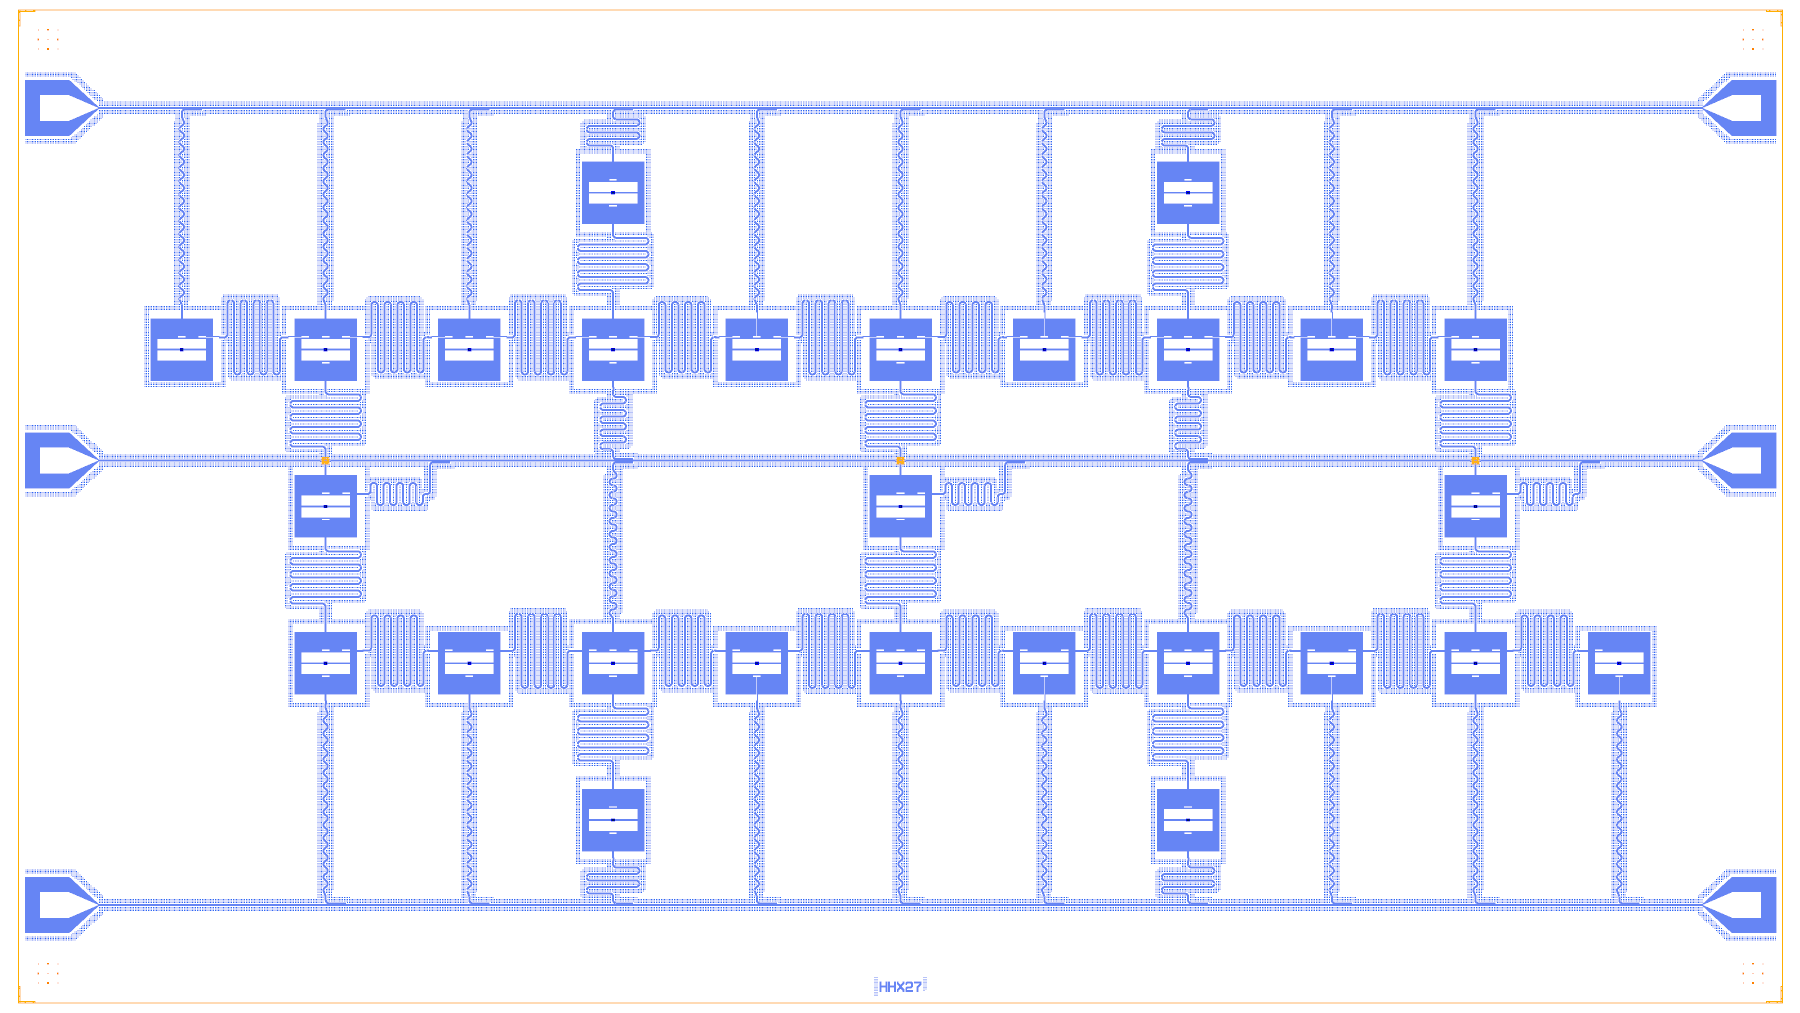

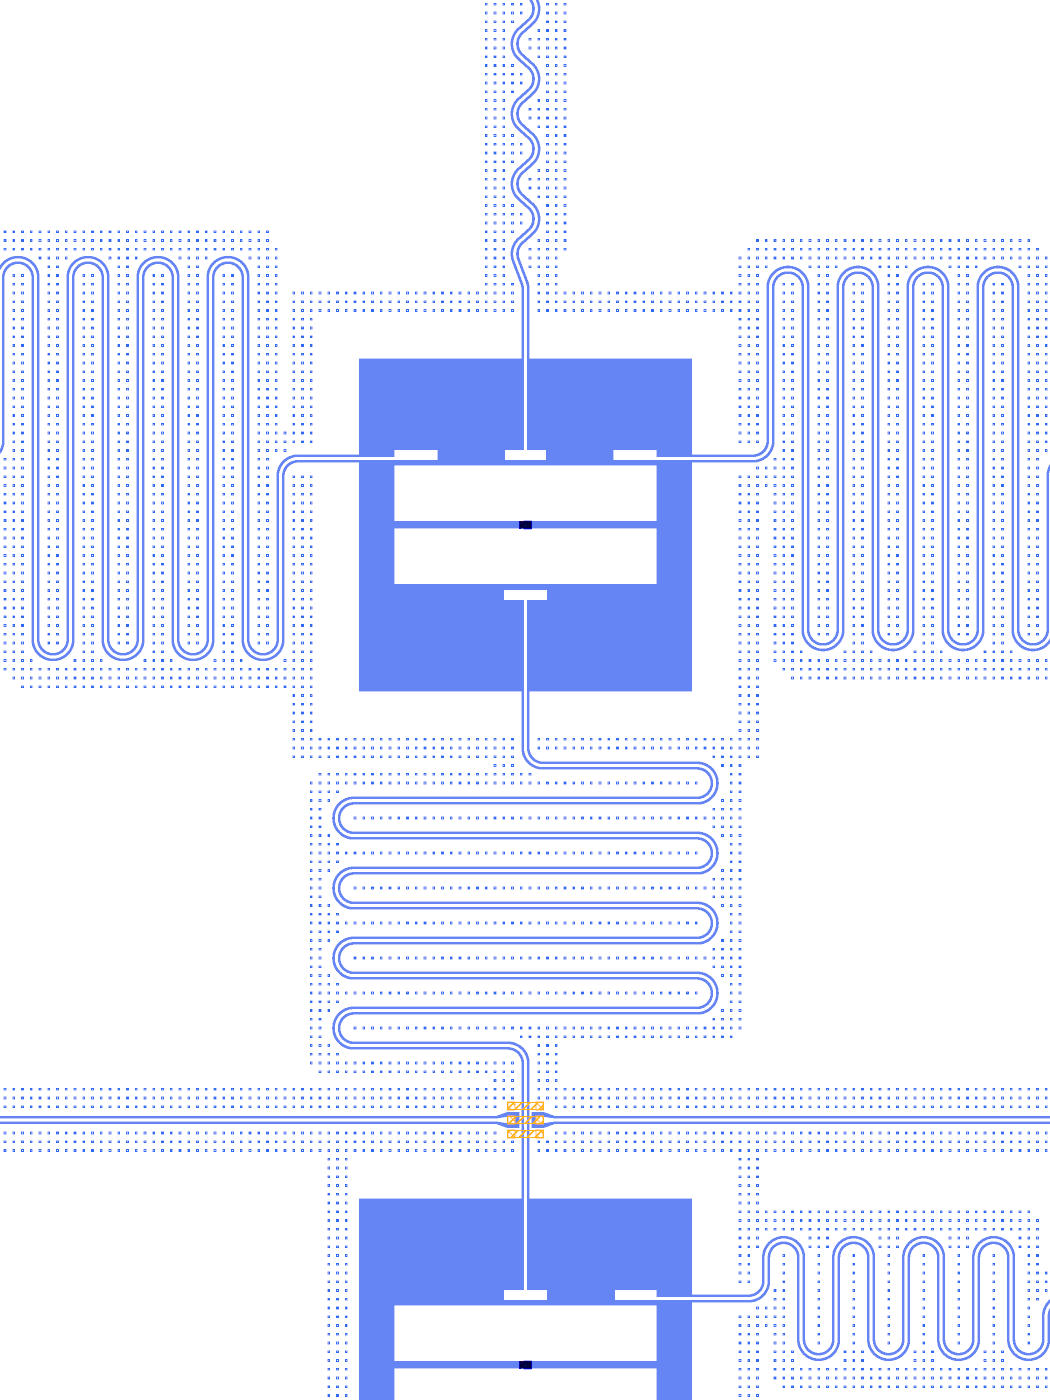

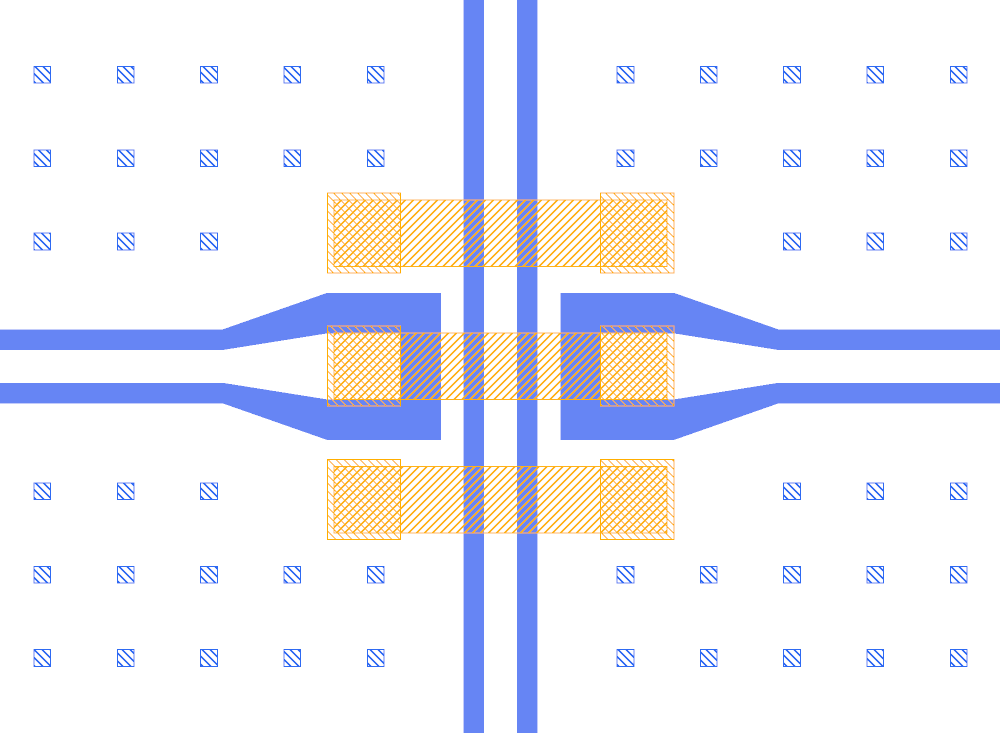

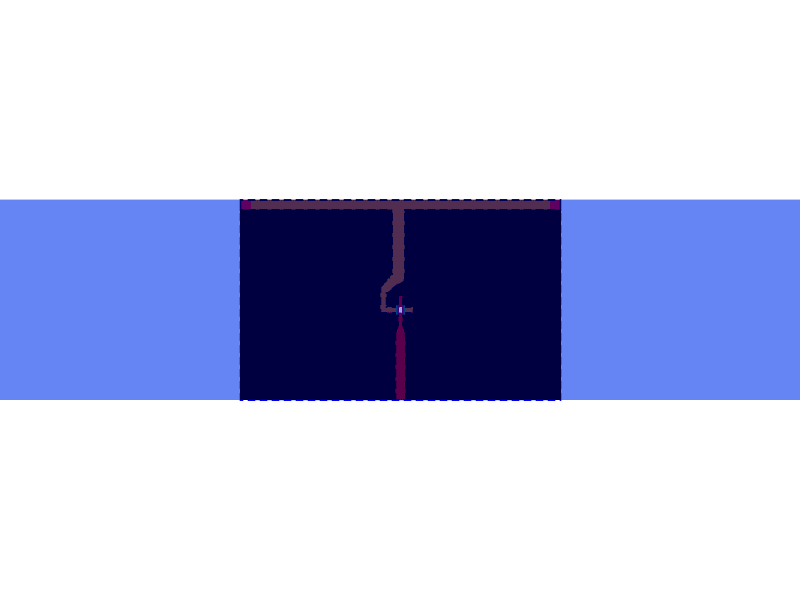

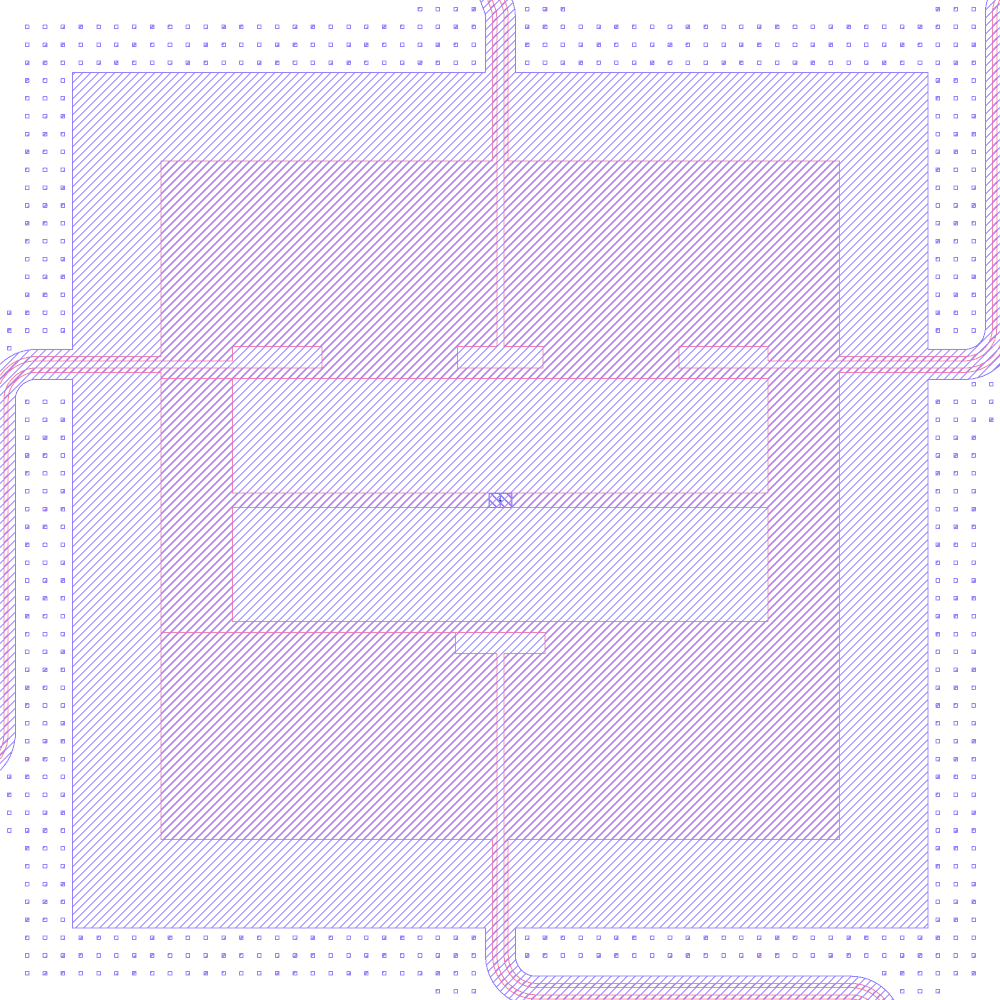

In [22]:
snap(d, OUT / "ibm_falcon_27q.png", size=(1800, 1013), width=900)
x12, y12 = xy(next(k for k, i in IBM.items() if i == 12))
snap(d, OUT / "ibm_falcon_27q_vertex.png", box=(x12 - 1500, y12 - 2500, x12 + 1500, y12 + 1500),
     size=(1050, 1400), width=450)
x13 = xy(next(k for k, i in IBM.items() if i == 13))[0]
snap(d, OUT / "ibm_falcon_27q_bridge.png", box=(x13 - 150, Y_FEED["mid"] - 110, x13 + 150, Y_FEED["mid"] + 110),
     size=(1000, 733), width=360)
snap(d, OUT / "ibm_falcon_27q_jj.png", box=(x12 - 40, y12 - 30, x12 + 40, y12 + 30), size=(800, 600), width=320)
snap_file(Path("build") / "ibm_falcon_27q_fab.oas", OUT / "ibm_falcon_27q_cheese.png",
          box=(x12 - 700, y12 - 700, x12 + 700, y12 + 700), size=(1000, 1000), width=400);

## 16 · Summary

- **Matches the source:** the ibmq_montreal coupling graph (generated and checked), every qubit within 30 MHz of
  IBM's frequency, every readout 1.5 % below IBM's (the Nb kinetic inductance entered the LOM after the lengths were
  set), J of the same order (0.90–1.64 vs 1.30–2.01 MHz).
- **Changed by the PDK:** trilayer junctions in the 40–50 kΩ window, hence α ≈ −145 MHz (IBM −330 MHz) and six
  colliding edges with IBM's frequency plan (step 13 shows the two ways out); the 27 × 15.2 mm die and frame; pads
  100 µm from the edges (the readout hangers placed by position, so they stay at their qubits); the PDK band cheese (no original exists).
- **Open PDK design warnings:** none. The FEM jobs are exported, not solved (`RUN_FEM = False`).
- **Known limits:** drive through the readout feedlines (no interposer); the bus frequencies are assumed (IBM does not
  publish them).